##### Master Degree in Computer Science and Data Science for Economics and Health

# Classification in disguise: predicting the next word

### Prof. Alfio Ferrara

## Introduction

In the notebooks of the first part of the course we built classifiers: given a text (the ingredients of a recipe) the network estimates $P(\text{cuisine} \mid \text{text})$, and the label is the most probable class. In Word2Vec we changed the task but not the machinery: given a word, the network estimates a distribution over the words that occur around it, and the labels came from the text itself, with no annotation.

In this part of the course we keep **a single** of those words, the one that comes right after. Given the beginning of a text, **which word comes next?** This is a classification problem in disguise: the classes are the words of the vocabulary, the input is what we have read so far, and the network estimates

$$P(w_t \mid w_1, \dots, w_{t-1})$$

A model of this distribution is a **language model**. It looks like a small variation of what we have already done, and it is the idea behind the models that write text today. What changes is not the network, but what we can do with it: since it says *how probable each word is after a text*, we can **score** a text (how likely is it?) and **generate** one, by choosing a word, appending it, and asking again.

The three notebooks of this part follow one idea. In this one we reduce the prediction of the next word to the classification we already know, and we see how far it goes when the input is a single word. In the next one we give a name and a formal framework to this model (the **Markov** language models, built on counts). In the third one we use a network like the one of Word2Vec to estimate the same distribution, and we see what it can do and what it cannot. We use two corpora: the **recipes** of the previous notebooks and, as a second domain, the **plots of films**, to see how much of what we find depends on the text.

## A toy example

As in the previous notebooks we start from an invented example, small enough to see everything. It is the world of the Word2Vec toy: three people, four drinks, four foods and five verbs, in sentences of three words. The rule that generates the sentences is the same, with one addition that we will need later: when the verb is `buys` or `likes`, **what is bought depends on the person**. `anna` only buys drinks, `luca` only buys foods, `marco` buys both.

In [1]:
import numpy as np
import pandas as pd
from torch import nn
import matplotlib.pyplot as plt
from collections import Counter

people = ["anna", "marco", "luca"]
drinks = ["coffee", "tea", "milk", "juice"]
foods = ["bread", "pasta", "rice", "cake"]
likes_of = {"anna": drinks, "marco": drinks + foods, "luca": foods}      # what a person buys or likes

rng = np.random.default_rng(0)
sentences = []
for _ in range(400):
    person, kind = rng.choice(people), rng.random()
    if kind < 0.3:
        sentences.append([person, "drinks", rng.choice(drinks)])
    elif kind < 0.6:
        sentences.append([person, "eats", rng.choice(foods)])
    elif kind < 0.8:
        sentences.append([person, "cooks", rng.choice(foods)])
    else:
        sentences.append([person, rng.choice(["buys", "likes"]), rng.choice(likes_of[person])])

for sentence in sentences[:8]:
    print(" ".join(sentence))

luca drinks milk
anna drinks coffee
anna likes milk
marco cooks rice
marco buys rice
luca buys rice
anna cooks cake
anna buys milk


### The labels come for free

To turn the text into a classification problem we need examples, each one made of an input and a label. The text provides both: **the label of a position is the word that occurs there, and the input is the word that precedes it**. The sentence `anna drinks tea` gives three examples if we mark its boundaries with two special symbols, `<s>` (start) and `</s>` (end), that are treated as words:

| input (previous word) | label (next word) |
|---|---|
| `<s>` | `anna` |
| `anna` | `drinks` |
| `drinks` | `tea` |
| `tea` | `</s>` |

The boundaries are not a detail: the first row says how a sentence begins, and the last how it ends. A model that knows `</s>` can decide when to stop.

In [2]:
vocabulary = ["<s>", "</s>"] + sorted({word for sentence in sentences for word in sentence})
index = {word: i for i, word in enumerate(vocabulary)}

def make_pairs(sentences):
    return np.array([(index[previous], index[word])
                     for sentence in sentences
                     for previous, word in zip(["<s>"] + sentence, sentence + ["</s>"])])

pairs = make_pairs(sentences)
print(f"{len(sentences)} sentences, {len(pairs)} examples, {len(vocabulary)} classes (the words and the two boundaries)")

pd.DataFrame([(vocabulary[p], vocabulary[w]) for p, w in make_pairs([sentences[0]])],
             columns=["input (previous word)", "label (next word)"])

400 sentences, 1600 examples, 18 classes (the words and the two boundaries)


,input (previous word),label (next word)
0,<s>,luca
1,luca,drinks
2,drinks,milk
3,milk,</s>


### The model

It is the first network of the classification notebook, the one without hidden layers, with the words in place of the cuisines.

- The input is the **one-hot** vector of the previous word $x$.
- The output has a neuron for each word of the vocabulary, with a **softmax**. Since the input is one-hot, the vector of the scores (the *logits*) of the word $x$ is simply a row of the weight matrix $W$, which has $V \times V$ entries, where $V$ is the number of words:

$$P(w \mid x) = \mathrm{softmax}(W_x)_w = \frac{\exp(W_{x,w})}{\sum_{w'} \exp(W_{x,w'})}$$

- The loss is the cross-entropy, the average of $-\log P(w_t \mid w_{t-1})$ over the examples, and the error of the output layer is again $p - y$, where $y$ is the one-hot vector of the label.

Nothing here is new. What is new is that $W$ has **a row for each possible context and a column for each possible next word**: it is a table, and we are going to read it as such.

In [3]:
def softmax(Z):
    E = np.exp(Z - Z.max(axis=1, keepdims=True))
    return E / E.sum(axis=1, keepdims=True)

def train_table(pairs, vocabulary_size, epochs=20000, learning_rate=2.0):
    previous, label = pairs[:, 0], pairs[:, 1]
    n = len(pairs)
    W = np.zeros((vocabulary_size, vocabulary_size))
    history = []
    for epoch in range(epochs):
        P = softmax(W[previous])                              # a distribution over the next word, for each example
        history.append(-np.log(P[np.arange(n), label]).mean())
        error = P.copy()
        error[np.arange(n), label] -= 1                       # p - y
        error /= n
        gradient = np.zeros_like(W)
        np.add.at(gradient, previous, error)                  # the examples with the same previous word update the same row
        W -= learning_rate * gradient
    return W, np.array(history)

W_toy, history = train_table(pairs, len(vocabulary))

# The lowest loss that a model that looks only at the previous word can reach: the conditional entropy of the next word
counts = np.zeros((len(vocabulary),) * 2)
np.add.at(counts, (pairs[:, 0], pairs[:, 1]), 1)
frequencies = counts / counts.sum(axis=1, keepdims=True).clip(min=1)
floor = -(counts / len(pairs) * np.log(np.where(frequencies > 0, frequencies, 1))).sum()
print(f"Final loss {history[-1]:.3f}; lowest possible loss for these data {floor:.3f}; loss of a random model {np.log(len(vocabulary)):.3f}")

Final loss 1.029; lowest possible loss for these data 1.028; loss of a random model 2.890


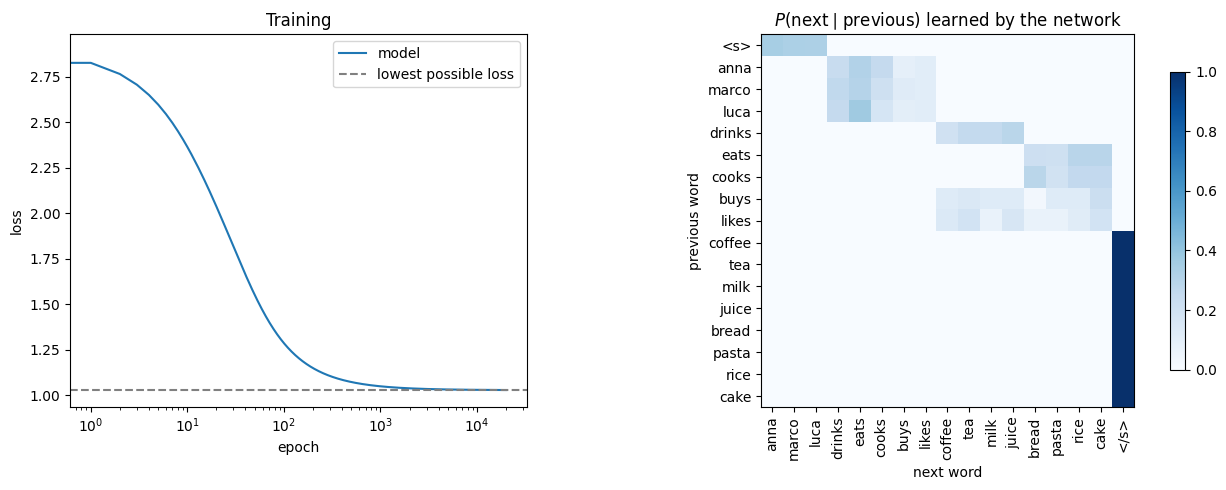

In [4]:
P_toy = softmax(W_toy)
order = ["<s>"] + people + ["drinks", "eats", "cooks", "buys", "likes"] + drinks + foods + ["</s>"]
rows = [index[w] for w in order if w != "</s>"]                        # </s> is never a previous word
columns = [index[w] for w in order if w != "<s>"]                      # <s> is never a next word

fig, ax = plt.subplots(ncols=2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].plot(history, label="model")
ax[0].axhline(floor, color="gray", linestyle="--", label="lowest possible loss")
ax[0].set_xscale("log")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("loss")
ax[0].set_title("Training")
ax[0].legend()

image = ax[1].imshow(P_toy[np.ix_(rows, columns)], cmap="Blues", vmin=0, vmax=1)
ax[1].set_xticks(range(len(columns)), [vocabulary[i] for i in columns], rotation=90)
ax[1].set_yticks(range(len(rows)), [vocabulary[i] for i in rows])
ax[1].set_xlabel("next word")
ax[1].set_ylabel("previous word")
ax[1].set_title("$P(\\mathrm{next} \\mid \\mathrm{previous})$ learned by the network")
plt.colorbar(image, ax=ax[1], shrink=0.8)
plt.tight_layout()

On the left, the **loss** goes from 2.89, the value of a model that gives the same probability to all the 18 classes ($\log 18$), to 1.029. The dashed line is the lowest loss that any model could reach by looking only at the previous word (1.028): even the best model cannot be certain of the next word, because `anna` can be followed by any verb. The horizontal axis is logarithmic, since the first epochs do most of the work.

On the right, the **table** $P(\text{next} \mid \text{previous})$ that the network has learned, with the words grouped by kind. We can read the structure of the text from it. After `<s>` there is a person; after a person there is a verb; after `drinks` a drink, after `eats` and `cooks` a food; after `buys` and `likes` either one (two blocks of lighter blue); after any drink or food the sentence ends (the dark column on the right). The three rows of the people are almost equal: the model knows which word it has read, and `anna`, `marco` and `luca` are followed by the same verbs.

In [5]:
# The same table, obtained only by counting: how many times each word follows each previous word, divided by the row total
difference = np.abs(P_toy - frequencies)[counts.sum(axis=1) > 0].max()
print(f"Largest difference between the probabilities of the network and the relative frequencies: {difference:.4f}")

def row(word, table, n=5):
    p = table[index[word]]
    return ", ".join(f"{vocabulary[i]} {p[i]:.2f}" for i in np.argsort(-p)[:n] if p[i] > 0.005)

pd.DataFrame({"network": {w: row(w, P_toy) for w in ["<s>", "drinks", "buys", "tea"]},
              "counts": {w: row(w, frequencies) for w in ["<s>", "drinks", "buys", "tea"]}}
             ).rename_axis("previous word").style.format(escape="html").format_index(escape="html").set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

Largest difference between the probabilities of the network and the relative frequencies: 0.0012


,network,counts
previous word,,
<s>,"anna 0.34, marco 0.33, luca 0.32","anna 0.34, marco 0.33, luca 0.33"
drinks,"juice 0.29, tea 0.26, milk 0.26, coffee 0.20","juice 0.29, tea 0.26, milk 0.26, coffee 0.20"
buys,"cake 0.22, tea 0.15, pasta 0.12, milk 0.12, coffee 0.12","cake 0.22, tea 0.15, pasta 0.12, milk 0.12, coffee 0.12"
tea,</s> 1.00,</s> 1.00


The network has found **exactly the table of the counts**. The largest difference between its probabilities and the relative frequencies (how many times a word follows another, divided by how many times the previous word occurs) is 0.0012, and it goes to zero as we train longer. The reason is that the cross-entropy is minimized, among all the tables, by the relative frequencies, and the lowest possible loss that we computed above is the loss of that table. A softmax regression on the previous word is, in the end, **a way of estimating a table of counts by gradient descent**. We will come back to this in the next notebook.

The table also shows what the model does not know. After `buys` it gives 0.22 to `cake` and 0.15 to `tea`, drinks and foods together, because it has forgotten **who** is buying.

### Using the model: from the probabilities to a text

Once we have the distribution of the next word, we can build a sentence: we start from `<s>`, choose a word, and use it as the new input, until the model chooses `</s>`. As in the classification notebook, we can choose the **most probable** word (*greedy*) or **draw** it from the distribution (*sampling*).

In [6]:
def generate(P, rng=None, max_words=8):
    """Starts from <s> and chooses the next word until </s>. Greedy if there is no random generator, sampling otherwise."""
    word, text = index["<s>"], []
    for _ in range(max_words):
        word = P[word].argmax() if rng is None else rng.choice(len(P), p=P[word])
        if vocabulary[word] == "</s>":
            break
        text.append(vocabulary[word])
    return text

print("greedy:  ", " ".join(generate(P_toy)))
sampler = np.random.default_rng(1)
for _ in range(8):
    print("sampling:", " ".join(generate(P_toy, sampler)))

greedy:   anna eats cake
sampling: luca likes cake
sampling: anna drinks tea
sampling: luca buys rice
sampling: anna eats cake
sampling: anna drinks juice
sampling: marco cooks cake
sampling: marco eats pasta
sampling: anna likes juice


The greedy choice produces always the same sentence, `anna eats cake`: at each step it takes the most probable word, so there is no variety. The sampling produces different sentences, and all the ones above are fine. They are the sentences of the text, with the frequencies of the text: an `anna` that drinks and eats, a `luca` that buys rice. Notice that the model has never been told what a sentence is: it learned that a sentence has three words, and when it ends, because after the third word the symbol `</s>` is certain.

In [7]:
def possible(sentence):
    """True if the rule that generated the data could have produced the sentence."""
    if len(sentence) != 3 or sentence[0] not in people:
        return False
    person, verb, thing = sentence
    return (thing in drinks if verb == "drinks" else thing in foods if verb in ("eats", "cooks")
            else thing in likes_of[person] if verb in ("buys", "likes") else False)

sampler = np.random.default_rng(2)
generated = [generate(P_toy, sampler) for _ in range(20000)]
wrong = [s for s in generated if not possible(s)]
print(f"{len(wrong)} of {len(generated)} sentences ({len(wrong) / len(generated):.1%}) could not have been produced by the rule")
print("; ".join(" ".join(s) for s in wrong[:8]))

# The same with the exact relative frequencies, that is, without any error of the training
exact = [generate(frequencies, sampler) for _ in range(20000)]
print(f"With the exact frequencies: {sum(not possible(s) for s in exact) / len(exact):.1%}")

1461 of 20000 sentences (7.3%) could not have been produced by the rule
anna buys pasta; luca eats likes tea; anna likes rice; anna buys rice; luca likes tea; luca likes milk; anna likes pasta; anna buys rice


With the exact frequencies: 6.8%


Drawing 20,000 sentences we find that **1,461 of them (7.3%)** could not have been produced by the rule: `anna buys pasta` (`anna` never buys foods), `luca likes tea` (`luca` never buys drinks). These sentences are as well formed as the others and each pair of consecutive words is fine (`anna buys`, `buys pasta` are in the text), but the sentence as a whole is not. The model chooses `pasta` knowing only that the previous word is `buys`, not that it was `anna` who is buying.

The mistakes are not due to the training: with the exact frequencies the share of impossible sentences is 6.8%, and the rest (0.5 points, with sentences like `luca eats likes tea`) is the residual error of the gradient descent. It is the **limit of a model that looks at a single word**. The sentences with `buys` or `likes` are 20% of the text, and in them the model chooses the object without knowing the person: it fails in about a third of them (6.8 / 20), which is the share of the cases in which the person is `anna` or `luca` and the kind of the object is the wrong one.

In [8]:
# The same lowest loss when the model sees the previous TWO words instead of one
pair_counts, context_counts = Counter(), Counter()
for sentence in sentences:
    text = ["<s>", "<s>"] + sentence + ["</s>"]
    for i in range(2, len(text)):
        pair_counts[tuple(text[i - 2:i + 1])] += 1
        context_counts[tuple(text[i - 2:i])] += 1
floor_two = -sum(n / len(pairs) * np.log(n / context_counts[k[:2]]) for k, n in pair_counts.items())
print(f"Lowest possible loss with one previous word: {floor:.3f}; with two: {floor_two:.3f}")

Lowest possible loss with one previous word: 1.028; with two: 0.996


With **two** previous words, `anna buys` instead of `buys`, the lowest possible loss goes down from 1.028 to 0.996: the sentence `anna buys pasta` would have probability zero. The gain is small only because the dependence exists in a fifth of the text. In real texts the dependence is everywhere, and what is needed to predict a word is much more than the previous one. This is the question that opens the rest of the notebook, and the following ones: **how many words of context do we need, and what does it cost to use them?**

## From the toy to real text

We now do the same on real text, in the two domains that we will use in the three notebooks.

- The **recipes**: the instructions of the 9,951 recipes of the previous notebooks (about 1.04 million words), short imperative sentences (*mix the eggs with the sugar until foamy*).
- The **plots of films**: the plot summaries of the *CMU Movie Summary Corpus* (Bamman, O'Connor and Smith, 2013, Creative Commons Attribution-ShareAlike), written by the contributors of Wikipedia. We use a random sample of 2,881 English films, so that the corpus has about the same size as the recipes (1.04 million words). They are longer sentences, full of names (*richthofen becomes outwardly energized by the war*).

We start from the recipes. The protocol is the one of the classification notebook, with the documents in place of the examples: the recipes are split at random in **80% for the training, 10% for the validation and 10% for the test**. Sentences of the same recipe never end up in different sets. The training set is used to learn, the validation set to take decisions (here: when to stop), and the **test set is looked at once, at the end**.

The text is processed as in Word2Vec: sentences split at the full stops, colons and semicolons, lowercase words made of letters (with the apostrophes inside the words, `mother's`). The vocabulary is made of the **4,000 most frequent words of the training set**, and all the other words become a single symbol `<unk>`. Words are not the only choice: one could use the subword tokens of the first notebooks (BPE, WordPiece), which have no unknown words, or characters. We keep words because they make the examples easy to read, and because the models of the next notebooks are compared on the same units.

In [9]:
import torch
from nlp import lm

recipes = lm.load_recipes()
train_docs, validation_docs, test_docs = lm.split_documents(recipes)
vocab = lm.Vocabulary(train_docs, size=4000)
V = len(vocab)

train, validation, test = (lm.next_word_pairs(docs, vocab) for docs in (train_docs, validation_docs, test_docs))

print(f"{len(train_docs)} / {len(validation_docs)} / {len(test_docs)} recipes for the training, the validation and the test")
print(f"{len(train[0])} / {len(validation[0])} / {len(test[0])} examples (previous word, next word)")
print(f"Vocabulary: {V} words; share of the words of the training text that are in it: {vocab.coverage(train_docs):.1%}")

example = next(s for doc in validation_docs for s in doc if any(w not in vocab.index for w in s))
print()
print("A sentence:                     ", " ".join(example))
print("The same, as the model reads it:", " ".join(vocab.decode(vocab.encode(example))))

7960 / 995 / 996 recipes for the training, the validation and the test
920631 / 115361 / 112129 examples (previous word, next word)
Vocabulary: 4000 words; share of the words of the training text that are in it: 98.9%

A sentence:                      bout min till tender
The same, as the model reads it: <s> <unk> min till tender </s>


The training set has 7,960 recipes and 920,631 examples (previous word, next word); the validation set has 995 recipes and 115,361 examples, the test set 996 recipes and 112,129 examples. The vocabulary has 4,000 words and covers 98.9% of the words of the training text: the other 1.1% become `<unk>`. In the example `bout` (a rare word) is one of them. The model reads `<s> <unk> min till tender </s>`, and for the model all the rare words are the same word.

### The model

The model is the one of the toy example, a softmax regression on the one-hot of the previous word, that is, a table $W$ with a row for each previous word. In PyTorch it is an `Embedding` with $V$ rows and $V$ columns, whose rows are the scores of the next word. We train it with Adam on minibatches, as in the classification notebook, and we measure it with the **perplexity** (the exponential of the average cross-entropy), computed on the validation set. We need a point of reference: the **frequency of the words**, a model that ignores the previous word and gives to each word its relative frequency in the training text. If the previous word is useful, the model has to do better.

Frequency of the words: perplexity 304.6 on the validation set
Table, epoch 2: 68.4; epoch 20: 86.8 (training: 40.4)

       train  validation  seen  unseen
epoch                                 
1       4.04        4.30  3.82    9.88
2       3.83        4.23  3.67   10.79
20      3.70        4.46  3.60   14.61


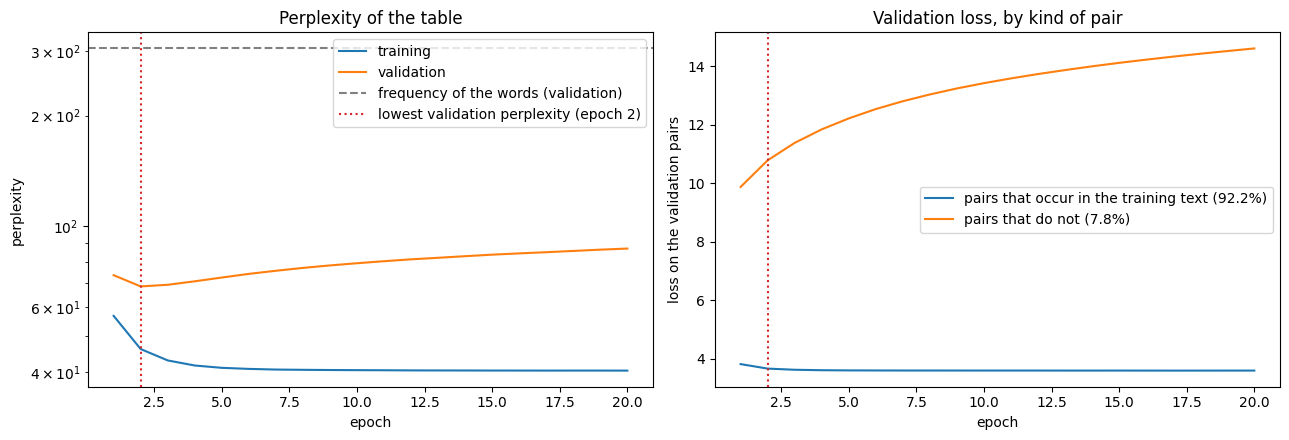

In [10]:
counts = np.zeros((V, V), dtype=np.int32)                      # how many times each word follows each previous word
np.add.at(counts, train, 1)

frequency = np.bincount(train[1], minlength=V) + 1             # +1 so that no word has probability zero
frequency = frequency / frequency.sum()
unigram_perplexity = np.exp(-np.log(frequency[validation[1]]).mean())

# Measures that we take after each epoch: the loss on the validation pairs that occur in the training text and on the others
seen = counts[validation[0], validation[1]] > 0
validation_seen = (validation[0][seen], validation[1][seen])
validation_unseen = (validation[0][~seen], validation[1][~seen])

def by_group(model):
    return {"seen": lm.loss_of(model, *validation_seen), "unseen": lm.loss_of(model, *validation_unseen)}

model = lm.Table(V)
history = pd.DataFrame(lm.train_next_word(model, train, validation, epochs=20, extra=by_group)).set_index("epoch")

fig, ax = plt.subplots(ncols=2, figsize=(13, 4.5))
ax[0].plot(np.exp(history["train"]), label="training")
ax[0].plot(np.exp(history["validation"]), label="validation")
ax[0].axhline(unigram_perplexity, color="gray", linestyle="--", label="frequency of the words (validation)")
ax[0].axvline(model.best_epoch, color="tab:red", linestyle=":", label=f"lowest validation perplexity (epoch {model.best_epoch})")
ax[0].set_yscale("log")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("perplexity")
ax[0].set_title("Perplexity of the table")
ax[0].legend()

ax[1].plot(history["seen"], label=f"pairs that occur in the training text ({seen.mean():.1%})")
ax[1].plot(history["unseen"], label=f"pairs that do not ({1 - seen.mean():.1%})")
ax[1].axvline(model.best_epoch, color="tab:red", linestyle=":")
ax[1].set_xlabel("epoch")
ax[1].set_ylabel("loss on the validation pairs")
ax[1].set_title("Validation loss, by kind of pair")
ax[1].legend()
plt.tight_layout()

print(f"Frequency of the words: perplexity {unigram_perplexity:.1f} on the validation set")
print(f"Table, epoch {model.best_epoch}: {np.exp(history.loc[model.best_epoch, 'validation']):.1f}; epoch 20: {np.exp(history.loc[20, 'validation']):.1f} (training: {np.exp(history.loc[20, 'train']):.1f})")
print()
print(history.loc[[1, model.best_epoch, 20], ["train", "validation", "seen", "unseen"]].rename_axis("epoch").round(2).to_string())

The frequency of the words is the point of reference: with no information on the previous word the perplexity is 304.6, as if each word were chosen among 305 equally probable ones. **Knowing the previous word** the table reaches 68.4 on the validation set, at epoch 2. The previous word is therefore very informative.

But then **the validation perplexity goes up**: 86.8 at epoch 20, while the training perplexity keeps going down (from 46.2 at epoch 2 to 40.4 at epoch 20). The model is learning the training set and not the language: this is **overfitting**. The red line is the epoch with the lowest validation perplexity, and the weights that we will use are the ones of that epoch.

The plot on the right says where the problem is. We split the validation examples in two groups: the **92.2%** whose pair (previous word, next word) occurs somewhere in the training text, and the **7.8%** whose pair does not. On the first group the loss improves slowly and then stays still (3.82 at epoch 1, 3.67 at epoch 2, 3.60 at epoch 20). On the second it **grows constantly**: 9.88, 10.79, 14.61. At epoch 20 the model gives to a pair that it has never seen a probability of about $e^{-14.6} \approx 5 \cdot 10^{-7}$, much lower than the one of a random word (1/4000). These 7.8% of the examples make 1.14 of the average loss of 4.46: a quarter of the loss.

### Why the table overfits

The table of the toy example had 324 scores and 1,600 examples. The one of the recipes has **$V^2 = 16$ million** scores, to be estimated from less than a million examples. Let us count how much of it the text can fill.

In [11]:
rows = counts.sum(axis=1)
print(f"Scores of the table: {V * V:,}; training examples: {len(train[0]):,}")
print(f"Pairs (previous word, next word) that occur at least once in the training text: {(counts > 0).sum():,} ({(counts > 0).mean():.2%} of the table)")
print(f"Validation examples whose pair never occurs in the training text: {(~seen).mean():.1%}")
print(f"Rows (previous words) with less than 10 examples: {(rows < 10).sum()} of {V}; median number of examples of a row: {np.median(rows):.0f}")

Scores of the table: 16,000,000; training examples: 920,631
Pairs (previous word, next word) that occur at least once in the training text: 119,001 (0.74% of the table)
Validation examples whose pair never occurs in the training text: 7.8%
Rows (previous words) with less than 10 examples: 1325 of 4000; median number of examples of a row: 18


Only 119,001 of the 16 million pairs, 0.74% of the table, occur in the training text, and 7.8% of the validation examples have a pair that has never been seen. A pair that is rare in the training text is not improbable in general, it is just not there. Half of the rows (the previous words) have at most 18 examples, and 1,325 words of 4,000 have less than 10.

What the gradient descent does is the following. For each example, it raises the score of the next word that we observe, and **lowers the scores of all the others**. A pair that is never observed is lowered every time its previous word occurs and never raised, and as the training goes on the model becomes more and more sure of what it has seen and less and less of the rest. At the end of the training (the *minimum* of the training loss) the table is the table of the counts of the toy example: **the probability of an unseen pair is zero**, and the loss on it infinite. We never get there, but we get closer at every epoch, and this is what the plot on the right shows. A model that gives probability zero to what it has not seen is a bad model of a language, where a new combination of known words is the normal case.

### What can we do

The problem is general: **a model with many more parameters than examples learns the examples**, and we have to decide what to do. There are a few ways, and we try them on the validation set.

1. **Stop earlier** (*early stopping*). We look at the validation loss after each epoch and keep the weights of the epoch where it is the lowest. It costs nothing but the validation set, which we need anyway.
2. **Penalize large weights** (*weight decay*, or $L_2$ regularization). A term $\lambda \lVert W \rVert^2$ in the loss keeps the scores close to zero, that is, the distributions close to the uniform one: a score cannot go to $-\infty$ for the pairs that we never see. It adds a hyperparameter, $\lambda$, to be chosen on the validation set.
3. **Smooth the counts.** If we compute the table by counting, we can add a small number $k$ to every count, $P(w \mid x) = (c_{x,w} + k) / (c_x + kV)$, so that no pair has probability zero. It is what the statistical language models do, and we will see it in the next notebook.
4. **Reduce the parameters.** Instead of a table with $V^2$ scores, go through a hidden layer of $d \ll V$ neurons, $V \to d \to V$, which has $2Vd$ parameters. It is what the network of the previous notebooks did. The previous word is no longer a row of the table but a short vector, and words that behave in the same way share the information.
5. **Get more text**, which is the best solution and is not always possible.

We try the first four on the recipes.

In [12]:
def fit(make_model, weight_decay=0.0, epochs=15):
    m = make_model()
    h = pd.DataFrame(lm.train_next_word(m, train, validation, epochs=epochs, weight_decay=weight_decay))
    return m, np.exp(h["validation"].min()), m.best_epoch, np.exp(h["train"].iloc[m.best_epoch - 1])

results = {"table, early stopping": (np.exp(history.loc[model.best_epoch, "validation"]), model.best_epoch, np.exp(history.loc[model.best_epoch, "train"]))}
for decay in [1e-7, 1e-6, 1e-5]:
    _, validation_perplexity, epoch, train_perplexity = fit(lambda: lm.Table(V), weight_decay=decay)
    results[f"table, weight decay {decay:g}"] = (validation_perplexity, epoch, train_perplexity)

for k in [0.001, 0.01, 0.1, 1]:
    smoothed = (counts + k) / (counts + k).sum(axis=1, keepdims=True)
    results[f"counts + {k:g}"] = (np.exp(-np.log(smoothed[validation[0], validation[1]]).mean()), None,
                                  np.exp(-np.log(smoothed[train[0], train[1]]).mean()))

_, validation_perplexity, epoch, train_perplexity = fit(lambda: nn.Sequential(nn.Embedding(V, 64), nn.Linear(64, V)))
results["hidden layer, d = 64"] = (validation_perplexity, epoch, train_perplexity)

pd.DataFrame(results, index=["validation perplexity", "epoch", "training perplexity"]).T.style.format(
    {"validation perplexity": "{:.1f}", "training perplexity": "{:.1f}", "epoch": "{:.0f}"}, na_rep="").set_properties(**{"text-align": "left"})

,validation perplexity,epoch,training perplexity
"table, early stopping",68.4,2,46.2
"table, weight decay 1e-07",65.5,13,44.5
"table, weight decay 1e-06",76.1,14,63.7
"table, weight decay 1e-05",151.4,5,144.8
counts + 0.001,75.1,,40.5
counts + 0.01,68.0,,44.0
counts + 0.1,78.0,,60.4
counts + 1,146.5,,132.0
"hidden layer, d = 64",70.7,14,57.4


The table shows the validation perplexity (lower is better), the epoch where it is reached and the training perplexity of that epoch.

- All the methods that work end in the same region, **between 65 and 71**. The first thing to notice is that the *same* table, early stopped, smoothed by weight decay, or **computed by counting and smoothed by adding 0.01 to the counts** (68.0), gives the same perplexity (68.4 for the early stopping). This confirms that the network is learning a table of counts, and the early stopping is a way of smoothing it.
- The best result is the weight decay with $\lambda = 10^{-7}$ (65.5), three points below the early stopping. We have tried only values that differ by a factor of ten, with a single seed and no more than 15 epochs, and the effect of the weight decay in Adam depends on the number of epochs. The differences of a few points are not tested, and we do not claim that this is the best that can be done. Larger values are too strong: with $10^{-5}$ the perplexity is 151.4, and with 1 added to the counts it is 146.5, because the distributions become too close to the uniform one.
- The **hidden layer** with $d = 64$ neurons has 516,000 parameters instead of 16 million, and it gets 70.7. The best epoch is the 14th of 15, so it is probably not finished, and it overfits much less: its training perplexity (57.4) is not far from the validation one. We use this idea in the third notebook.

We keep the **early stopping**. It is the simplest solution, it has no hyperparameter to tune, it needs only the validation set that we are using anyway, and it leaves the model as a table, which is what we want to compare with the counts of the next notebook. It is not the one with the lowest perplexity, and we have said so.

## The table as a predictor

We keep the weights of the epoch with the lowest validation perplexity and we use the model, first of all, as a **predictor**, as we did in Word2Vec: before looking at anything else we check that it predicts words that make sense. The measures are the perplexity and the **top-$k$ accuracy**: the share of the examples in which the right next word is among the $k$ words that the model considers the most probable. The reference is again the frequency of the words, which always proposes the $k$ most frequent words. The word `<unk>` is never proposed, and the examples whose next word is `<unk>` are left out of the top-$k$, because predicting an unknown word is not what we are interested in (in the plots of films this is a large share of the examples: we will see it).

In [13]:
model.load_state_dict(model.best_state)

def evaluate(model, vocabulary, train, validation):
    known = validation[1] != vocabulary.unk
    known_pairs = (validation[0][known], validation[1][known])
    model_top = lm.top_k_accuracy(model, *known_pairs, exclude=vocabulary.unk)
    frequency_top = lm.frequency_top_k(train[1], known_pairs[1], len(vocabulary), exclude=vocabulary.unk)
    return pd.DataFrame({
        "perplexity": [np.exp(lm.loss_of(model, *validation)), lm.frequency_perplexity(train[1], validation[1], len(vocabulary))],
        **{f"top-{k}": [model_top[k], frequency_top[k]] for k in model_top}},
        index=["table (previous word)", "frequency of the words"])

print(f"Examples of the validation set whose next word is <unk>: {(validation[1] == vocab.unk).mean():.1%}")
evaluate(model, vocab, train, validation).style.format({"perplexity": "{:.1f}", "top-1": "{:.1%}", "top-5": "{:.1%}", "top-10": "{:.1%}"})

Examples of the validation set whose next word is <unk>: 1.3%


,perplexity,top-1,top-5,top-10
table (previous word),68.4,23.7%,47.9%,57.8%
frequency of the words,304.6,9.3%,24.1%,32.2%


In [14]:
def next_words(model, vocabulary, words, n=5):
    rows = {}
    for word in words:
        p = model.distribution(np.array([vocabulary.index[word]]))[0]
        rows[word] = ",  ".join(f"{vocabulary.words[i]} {p[i]:.2f}" for i in np.argsort(-p)[:n])
    return pd.DataFrame({"most probable next words": rows}).rename_axis("previous word").style.format(escape="html").format_index(
        escape="html").set_properties(**{"text-align": "left"}).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])

next_words(model, vocab, ["<s>", "preheat", "bring", "mix", "until", "cover", "add", "bake"])

,most probable next words
previous word,
<s>,"add 0.11, in 0.04, place 0.03, stir 0.03, serve 0.03"
preheat,"oven 0.68, the 0.20, a 0.02, your 0.01, grill 0.01"
bring,"to 0.67, the 0.06, a 0.05, water 0.03, back 0.02"
mix,"well 0.18, together 0.10, the 0.09, all 0.08, in 0.07"
until,"the 0.12, smooth 0.06, golden 0.05, tender 0.03, it 0.03"
cover,"and 0.38, with 0.21, the 0.11, </s> 0.07, tightly 0.02"
add,"the 0.28, to 0.05, salt 0.02, chicken 0.02, more 0.02"
bake,"for 0.30, at 0.25, in 0.12, minutes 0.06, until 0.05"


The previous word is a good predictor. The right next word is the first choice of the table in 23.7% of the validation examples, against 9.3% for the most frequent word, and it is among the first ten in 57.8%, against 32.2%. Only 1.3% of the examples have `<unk>` as next word, and they are left out.

Each row of the table is a distribution that we can read, and they say sensible things. After `preheat` comes `oven` (0.68) or `the` (0.20); after `bring`, `to` (0.67); after `bake`, `for` (0.30) or `at` (0.25); after `cover`, `and` (0.38) or `with` (0.21), and the sentence can end (`</s>`, 0.07). After `<s>` the model proposes the verbs that open an instruction: `add`, `in`, `place`, `stir`, `serve`, with low probabilities, because many sentences can start in many ways. It is a perfectly good predictor, **as long as one word is enough**. After `add` the most probable word is `the` (0.28), and what follows `the` is another question.

### From prediction to generation

A model of the next word is also a **generator**. We start from `<s>`, we ask the model for the distribution of the next word, we choose a word, we append it to the text and we use it as the new input, until the model chooses `</s>`. As in the classification notebook, the choice can be **greedy** (the most probable word, always the same text) or by **sampling**, and in the second case we can change the **temperature** $T$: the probabilities become $\mathrm{softmax}(\text{scores} / T)$. With $T = 1$ the words are drawn from the distribution of the model; with $T < 1$ the distribution is sharper, and the most probable words are even more probable; with $T > 1$ it is flatter, and the rare words have more chances. For $T \to 0$ we get the greedy choice.

In [15]:
real_lengths = [len(s) for doc in validation_docs for s in doc]

def show_samples(model, vocabulary, temperatures=(0.5, 1.0, 1.5), n=4, seed=0):
    print("greedy:", " ".join(lm.generate_text(model, vocabulary)))
    for T in temperatures:
        rng = np.random.default_rng(seed)
        print(f"\nT = {T}")
        for _ in range(n):
            print("   ", " ".join(lm.generate_text(model, vocabulary, rng, T)))

show_samples(model, vocab)

rng = np.random.default_rng(1)
lengths = np.array([len(lm.generate_text(model, vocab, rng)) for _ in range(2000)])
print(f"\nSampling with T = 1, 2000 sentences: mean length {lengths.mean():.1f} words (real sentences of the validation set: {np.mean(real_lengths):.1f}); "
      f"{(lengths >= 30).mean():.1%} reach the limit of 30 words (in the real sentences: {np.mean(np.array(real_lengths) >= 30):.1%} have 30 words or more)")

greedy: add the chicken and cook for minutes

T = 0.5
    stir in the <unk> and drain and garlic and season with <unk> and the meat and let stand for minutes
    add the skillet over chicken bouillon granules and pepper and stir in a large bowl
    bake at medium heat
    heat

T = 1.0
    preheat oven
    to get rid ricotta green beans crush coarsely
    deep
    whisk the smaller pieces

T = 1.5
    carefully cut the stir though shears okay approximate forget accompaniments far a natural serving avoid making thumped turnip crumbly method
    stir constantly frost leg toothpicks marg thought restaurant quesadilla patting horizontally that caps buy wipe crusty clusters southwestern removed actually dash sponge miso gas jumbo peaks chopsticks bread ceramic slash
    combine bringing them well the next quartered moist
    beat until chicken salsa salt only about doves diagonal bake again metallic piping disposable natural rich methi earth disposable skip doesn english date matcha crusts 


Sampling with T = 1, 2000 sentences: mean length 9.8 words (real sentences of the validation set: 9.9); 4.8% reach the limit of 30 words (in the real sentences: 1.1% have 30 words or more)


Each choice is reasonable, and the sentences are not. The greedy text, `add the chicken and cook for minutes`, is the same every time (at each step it takes the most probable word, which at the start is `add`, 0.11 of the cases). With $T = 0.5$ we find pieces that look like a recipe, `add the skillet over chicken bouillon granules and pepper and stir in a large bowl`, but they have no plan: they go on by adding things with `and`, and the second sentence (`stir in the <unk> and drain and garlic and season with <unk> and the meat and let stand for minutes`) does not say anything that could be done in a kitchen. With $T = 1$ the sentences are less regular: `preheat oven` is correct and short, `deep` is one word, and `to get rid ricotta green beans crush coarsely` begins well and then loses itself. With $T = 1.5$ the flatter distribution gives to the rare words (`thumped`, `lavender`, `gravlax`) the chances that they do not have, and the result is a list of words.

The measures say two things. The **length** of the sentences drawn with $T = 1$ is that of the real ones (9.8 words against 9.9): a sentence can end after any word that is often the last one, as `oven` or `minutes`. But the sentences that **never end** are too many: 4.8% reach the limit of 30 words, against 1.1% of the real ones with 30 words or more. The model has no way to know how long the sentence is, because it only sees the last word, and after `and` it can go on for ever.

## A second domain: the plots of films

We repeat the whole procedure on the plots, from the split of the documents to the early stopping (here the training stops by itself when the validation perplexity has not improved for two epochs). The code is the same, only the text changes.

In [16]:
plots = lm.load_plots()
plot_docs = lm.split_documents(plots)
plot_vocab = lm.Vocabulary(plot_docs[0], size=4000)
plot_train, plot_validation, plot_test = (lm.next_word_pairs(docs, plot_vocab) for docs in plot_docs)

plot_model = lm.Table(len(plot_vocab))
plot_history = pd.DataFrame(lm.train_next_word(plot_model, plot_train, plot_validation, epochs=10, patience=2)).set_index("epoch")
plot_model.load_state_dict(plot_model.best_state)

print(f"{len(plots)} plots: {len(plot_docs[0])} / {len(plot_docs[1])} / {len(plot_docs[2])} for the training, the validation and the test")
print(f"{len(plot_train[0])} / {len(plot_validation[0])} / {len(plot_test[0])} examples; the vocabulary covers {plot_vocab.coverage(plot_docs[0]):.1%} of the words of the training text "
      f"(recipes: {vocab.coverage(train_docs):.1%})")
print(f"Examples of the validation set whose next word is <unk>: {(plot_validation[1] == plot_vocab.unk).mean():.1%} (recipes: {(validation[1] == vocab.unk).mean():.1%})")
print(f"Training stopped after {len(plot_history)} epochs; the best is epoch {plot_model.best_epoch}")
print()
print(" ".join(plot_docs[0][0][0]), "\n", " ".join(plot_docs[0][0][1]))

pd.concat({"recipes": evaluate(model, vocab, train, validation),
           "plots": evaluate(plot_model, plot_vocab, plot_train, plot_validation)}).style.format(
    {"perplexity": "{:.1f}", "top-1": "{:.1%}", "top-5": "{:.1%}", "top-10": "{:.1%}"})

2881 plots: 2304 / 288 / 289 for the training, the validation and the test
880485 / 108275 / 108123 examples; the vocabulary covers 84.4% of the words of the training text (recipes: 98.9%)
Examples of the validation set whose next word is <unk>: 15.8% (recipes: 1.3%)
Training stopped after 4 epochs; the best is epoch 2

barry champlain a jewish radio personality in dallas texas is a host with a caustic sense of humor and a knack for cutting people down with his controversial politically liberal views 
 champlain's radio show is about to go nationwide


The model for the plots is built in the same way and it has the same behaviour: the best epoch is the second one, and the training stops after the fourth. The two texts are different in a few things that matter.

- **The vocabulary covers less text**: 84.4% of the words of the training text, against 98.9%. About half of the words that are left out look like names of people and places (they are written with a capital letter inside a sentence), the other half are ordinary words that occur rarely (`thank`, `wives`, `trainer`). 15.8% of the next words of the validation set are `<unk>` (1.3% in the recipes), so that very often the model can only say that an uncommon word comes, not which one.
- **The text is harder to predict.** The perplexity of the table is 123.9, against 258.0 of the frequency of the words: the previous word halves it. In the recipes it divides it by 4.5 (68.4 against 304.6). The top-10 accuracy is 46.1% (33.7% for the frequency), and 57.8% in the recipes. The two perplexities cannot be compared directly: in the plots 15.8% of the next words are replaced by a single symbol, that is easy to predict, and this lowers the perplexity. With a full vocabulary the difference between the two texts would be larger.

Instructions are short, they all begin with a verb and they repeat the same few patterns; the plots are made of longer sentences (17.8 words, against 9.9) with many more things to say.

In [17]:
show_samples(plot_model, plot_vocab, n=4)
rng = np.random.default_rng(1)
lengths = np.array([len(lm.generate_text(plot_model, plot_vocab, rng)) for _ in range(2000)])
plot_lengths = [len(s) for doc in plot_docs[1] for s in doc]
print(f"\nSampling with T = 1, 2000 sentences: mean length {lengths.mean():.1f} words (real sentences of the validation set: {np.mean(plot_lengths):.1f}); "
      f"{(lengths >= 30).mean():.1%} reach the limit of 30 words (in the real sentences: {np.mean(np.array(plot_lengths) >= 30):.1%} have 30 words or more)")

greedy: <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>

T = 0.5
    the <unk> <unk> <unk> and the <unk>
    the <unk> and <unk> and <unk>
    <unk> and <unk> <unk> <unk> <unk> <unk>
    the <unk> <unk> off on the <unk>

T = 1.0
    however the <unk> <unk> sets flee is waiting for kitchen virus <unk> assistant <unk> or the intended to his own <unk> <unk> only help him and battles vail illegal alien
    some of <unk> daughter of the high speed bet on a new york and her soul to face
    realizing it and moved to their <unk> in making the <unk> of <unk> <unk> who his attention
    mitch is <unk> into dan and somehow involved in from heaven champion he's got back in order to england after receiving <unk> or spike realized

T = 1.5
    breaking set the <unk> equipment nobody false bottom happen worst smuggling <unk> atmosphere
    victor eventually inspired col


Sampling with T = 1, 2000 sentences: mean length 14.9 words (real sentences of the validation set: 17.8); 19.8% reach the limit of 30 words (in the real sentences: 10.8% have 30 words or more)


The greedy text is `<unk>` repeated thirty times: the most probable word after `<s>` is `<unk>` (the sentence begins with a name), and the most probable word after `<unk>` is `<unk>` (probably two names in a row, as a first name and a surname), so the greedy choice never leaves. With $T = 0.5$ the sharper distribution gives the same few words (`the`, `and`, `<unk>`). The text of the plots with $T = 1$ has the voice of a summary, and some pieces are acceptable (`some of <unk> daughter of the high speed bet on a new york and her soul to face`), but it is easy to see that nobody is telling a story: `mitch is <unk> into dan and somehow involved in from heaven champion he's got back in order to england after receiving <unk>`. The names that appear (`mitch`, `dan`, `spike`) come from the vocabulary, and the same person never comes back. With $T = 1.5$ we get lists of rare words, among them `ndash`, which is not a word but the remains of a piece of markup of the Wikipedia pages (`{{spaced ndash}}`): the text has defects that we did not clean, and the model learns them.

The sentences that never end are even more than in the recipes: 19.8% reach the limit of 30 words, against 10.8% of the real ones with 30 words or more, and the average length is lower (14.9 words against 17.8), so there are both too many short and too many endless sentences.

## The test set

Up to now we have taken our decisions (the epoch, the size of the vocabulary, the model) on the validation set. The test set, kept aside from the beginning, is used **once**, for the two final models.

In [18]:
test_results = {}
for name, m, vocabulary, tr, te in [("recipes", model, vocab, train, test), ("plots", plot_model, plot_vocab, plot_train, plot_test)]:
    test_results[name] = {"table, test": np.exp(lm.loss_of(m, *te)),
                          "frequency of the words, test": lm.frequency_perplexity(tr[1], te[1], len(vocabulary))}
pd.DataFrame(test_results).T.style.format("{:.1f}")

,"table, test","frequency of the words, test"
recipes,65.9,297.5
plots,123.8,259.3


On the test set the perplexity of the table is **65.9 for the recipes** and **123.8 for the plots**, against 297.5 and 259.3 of the frequency of the words. They are the values that we had on the validation set (68.4 and 123.9), as it should be when the decisions taken on the validation set have not been fitted too hard to it. The differences between the validation and the test set (2.5 points in the recipes) come from the different recipes: it is a measure with its own noise, that we have not estimated.

## What we have learned

- **Predicting the next word is a classification.** The classes are the words of the vocabulary, the input is the previous word, and the labels come for free from the text. The same network, the same loss, the same perplexity of the classification notebook, with $V$ classes instead of 10.
- **With one word of context the model is a table of $V^2$ scores, and it learns the counts.** The softmax regression ends in the relative frequencies of the pairs of words. This is what makes it overfit: 0.74% of the table is ever seen, and a pair that is not in the training text gets probability zero. Early stopping, weight decay, smoothing of the counts and a hidden layer are ways of dealing with it, and we have kept the early stopping.
- **It predicts better than the frequency of the words** (perplexity 68 against 305 in the recipes, 124 against 258 in the plots) **and it generates text that is locally plausible**. The temperature is the knob between a text that always says the same thing and a text that says anything.
- **But it has no memory.** In the toy example 7% of the sentences are impossible because the model forgets who is buying; in the recipes and in the plots the sentences have no plan and too many of them never end.

The model that we have built is the simplest member of a family, in which the next word depends on the $n - 1$ words that precede it. For $n = 2$ it is a table of counts, and the questions that it leaves open are the ones of the next two notebooks.

1. **How many words of context do we need?** If we use two words, the table has $V^3$ cells, and the examples that we have do not grow. We need a formal framework to say what we are computing, and what we are assuming when we look at only $n - 1$ words: this is the **Markov assumption** of the statistical language models.
2. **Can we use more context without a table that grows with it?** The hidden layer of the previous notebooks and the vectors of Word2Vec go in this direction, and the third notebook will use them, and will show that this too has a limit.

For the discussion: *(a)* why does the loss on the pairs that the model has never seen keep growing while the one on the others stays flat? *(b)* even a perfect model would not have a top-1 accuracy of 100%: why? *(c)* how would you make the model complete a given beginning, such as `preheat the`?